# DSCI 552 – Homework 4

**Name:** Pooja Nandyappa Subashchandra  
**GitHub Username:** nandyapp-afk  
**USC ID:** 1768721225

In [1]:
import os
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from scipy.stats import norm
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, auc, confusion_matrix, roc_curve
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler, label_binarize

warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="The least populated class")

# Relative path (forward slashes only): data/AReM/<activity>/dataset<k>.csv
DATA_DIR = "data/AReM"

ACTIVITIES = ["bending1", "bending2", "cycling", "lying", "sitting", "standing", "walking"]
COLS = ["time", "avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]
SERIES = COLS[1:]                  # the 6 time series
STATS = ("min", "mean", "max")     # the three features selected in 1(c)iv
L_VALUES = range(1, 21)            # number of pieces each time series is broken into
SEED = 0
C_BIG = 1e6                        # "C -> infinity": effectively no L2 penalty
MAX_ITER = 100                     # stop early to avoid instability on separable classes


def l1_logreg(**kwargs):
    """L1-penalized LogisticRegression (scikit-learn >= 1.8 expresses L1 through l1_ratio=1)."""
    if tuple(int(v) for v in sklearn.__version__.split(".")[:2]) >= (1, 8):
        return LogisticRegression(l1_ratio=1.0, **kwargs)
    return LogisticRegression(penalty="l1", **kwargs)

## Part 1 – Feature creation (code from Homework 3, reused)

Load the AReM data, split into train / test (datasets 1, 2 of `bending1` and `bending2`, and datasets 1, 2, 3 of every other folder are test), and extract the three features selected in 1(c)iv (**minimum, mean, maximum**).
`build_features(l)` breaks every time series into `l` pieces of (approximately) equal length and computes the three features on each piece, so `l = 1` gives the features of the whole series.

In [2]:
def load_instance(path):
    """Read one AReM file (skips '#' lines, accepts comma or whitespace delimiters)."""
    rows = []
    with open(path, errors="ignore") as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith("#"):
                continue
            parts = [p for p in re.split(r"[,\s]+", line) if p]
            if len(parts) != len(COLS):
                continue
            try:
                rows.append([float(p) for p in parts])
            except ValueError:
                continue
    return pd.DataFrame(rows, columns=COLS)


def is_test(activity, k):
    if activity in ("bending1", "bending2"):
        return k in (1, 2)
    return k in (1, 2, 3)


records, series_list = [], []
for act in ACTIVITIES:
    folder = f"{DATA_DIR}/{act}"
    files = [f for f in os.listdir(folder) if re.match(r"dataset\d+\.csv$", f)]
    files.sort(key=lambda f: int(re.findall(r"\d+", f)[0]))
    for f in files:
        k = int(re.findall(r"\d+", f)[0])
        series_list.append(load_instance(f"{folder}/{f}")[SERIES].to_numpy())
        records.append({"activity": act, "dataset": k, "test": is_test(act, k)})

meta = pd.DataFrame(records)
is_train = ~meta["test"].to_numpy()
y_bin = meta["activity"].str.startswith("bending").astype(int).to_numpy()          # 1 = bending
y_multi = meta["activity"].map({a: i for i, a in enumerate(ACTIVITIES)}).to_numpy()
y_tr, y_te = y_bin[is_train], y_bin[~is_train]

In [3]:
def build_features(l):
    """Matrix (88 x 18*l): for each series, each of its l pieces, the min / mean / max."""
    rows = []
    for arr in series_list:                                    # arr: (480, 6)
        row = []
        for j in range(len(SERIES)):
            for piece in np.array_split(arr[:, j], l):
                row += [piece.min(), piece.mean(), piece.max()]
        rows.append(row)
    names = [f"{st}_s{j + 1}_p{i + 1}"
             for j in range(len(SERIES)) for i in range(l) for st in STATS]
    return np.array(rows), names


FEATS = {l: build_features(l) for l in L_VALUES}

## Part 2(a) – Binary classification using logistic regression (bending vs. other activities)

### 2(a)i Scatter plots of the selected features (time series 1, 2 and 6), training set

Red = bending, blue = other activities.

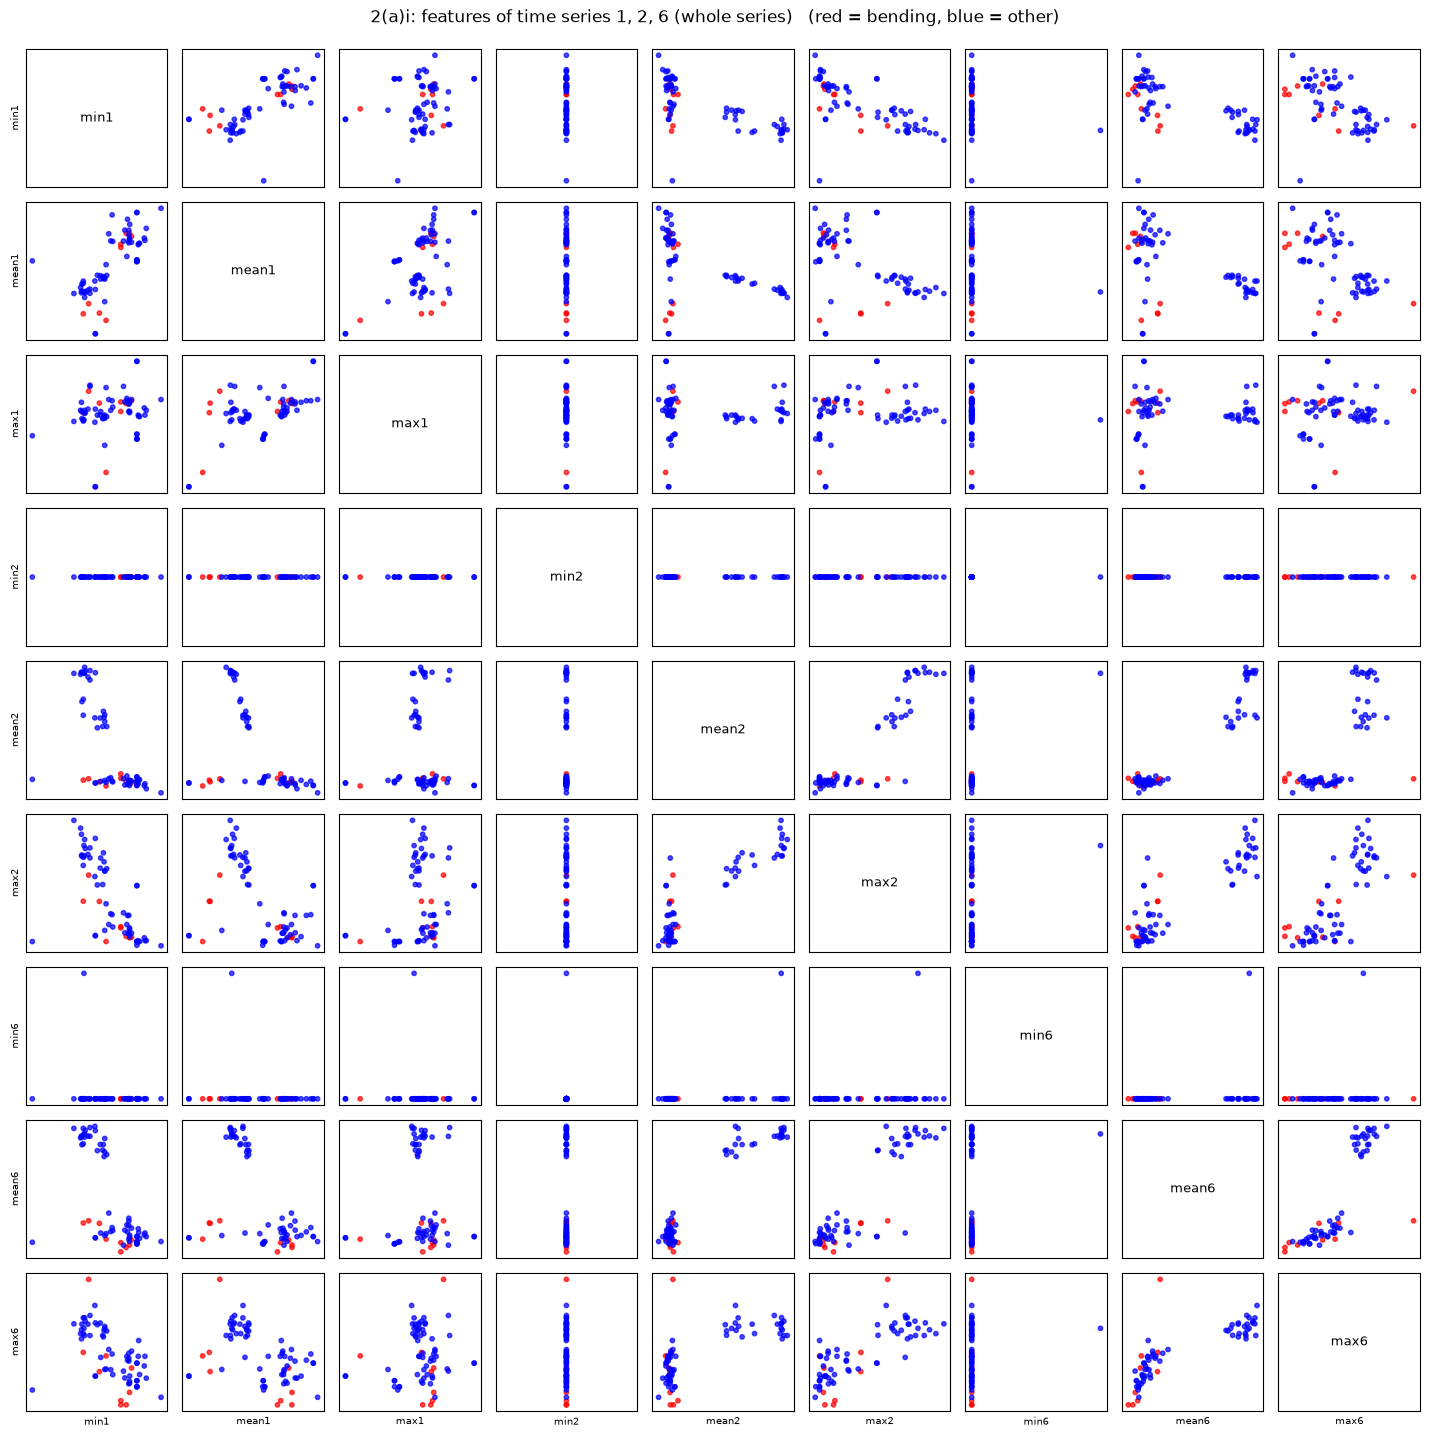

In [4]:
def scatter_matrix_by_class(X, names, y, title):
    k = len(names)
    fig, axes = plt.subplots(k, k, figsize=(1.6 * k, 1.6 * k))
    colors = np.where(y == 1, "red", "blue")
    for r in range(k):
        for c in range(k):
            ax = axes[r, c]
            if r == c:
                ax.text(0.5, 0.5, names[c], ha="center", va="center", fontsize=9)
            else:
                ax.scatter(X[:, c], X[:, r], c=colors, s=10, alpha=0.7)
            ax.set_xticks([])
            ax.set_yticks([])
            if r == k - 1:
                ax.set_xlabel(names[c], fontsize=7)
            if c == 0:
                ax.set_ylabel(names[r], fontsize=7)
    fig.suptitle(title + "   (red = bending, blue = other)", y=0.995)
    plt.tight_layout()
    plt.show()


def columns_for(l, series=(1, 2, 6), piece=1):
    names = FEATS[l][1]
    wanted = [f"{st}_s{j}_p{piece}" for j in series for st in STATS]
    return [names.index(w) for w in wanted], [w.rsplit("_p", 1)[0].replace("_s", "") for w in wanted]


idx, labels = columns_for(1)
scatter_matrix_by_class(FEATS[1][0][is_train][:, idx], labels, y_tr,
                        "2(a)i: features of time series 1, 2, 6 (whole series)")

### 2(a)ii Break each training time series into two pieces and repeat

Scatter plots of the same features computed on the first half and on the second half of time series 1, 2 and 6.

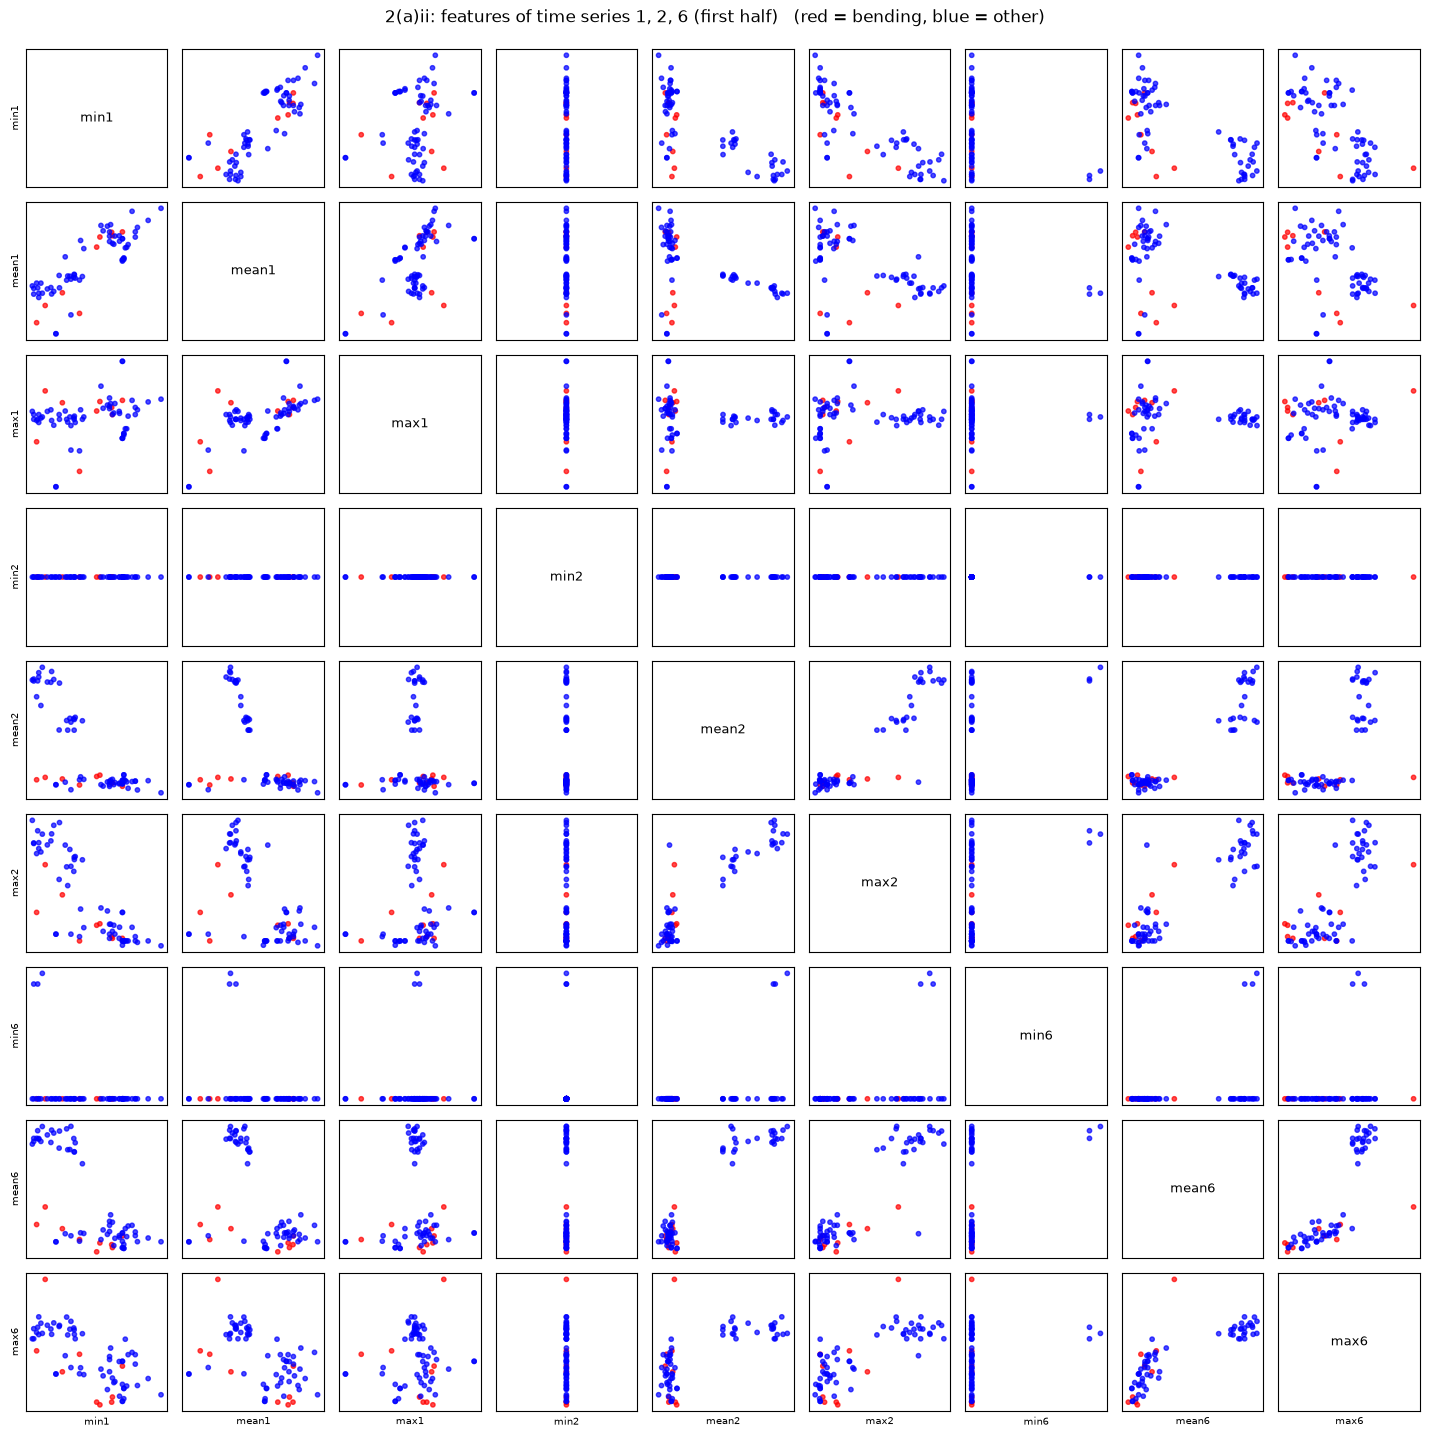

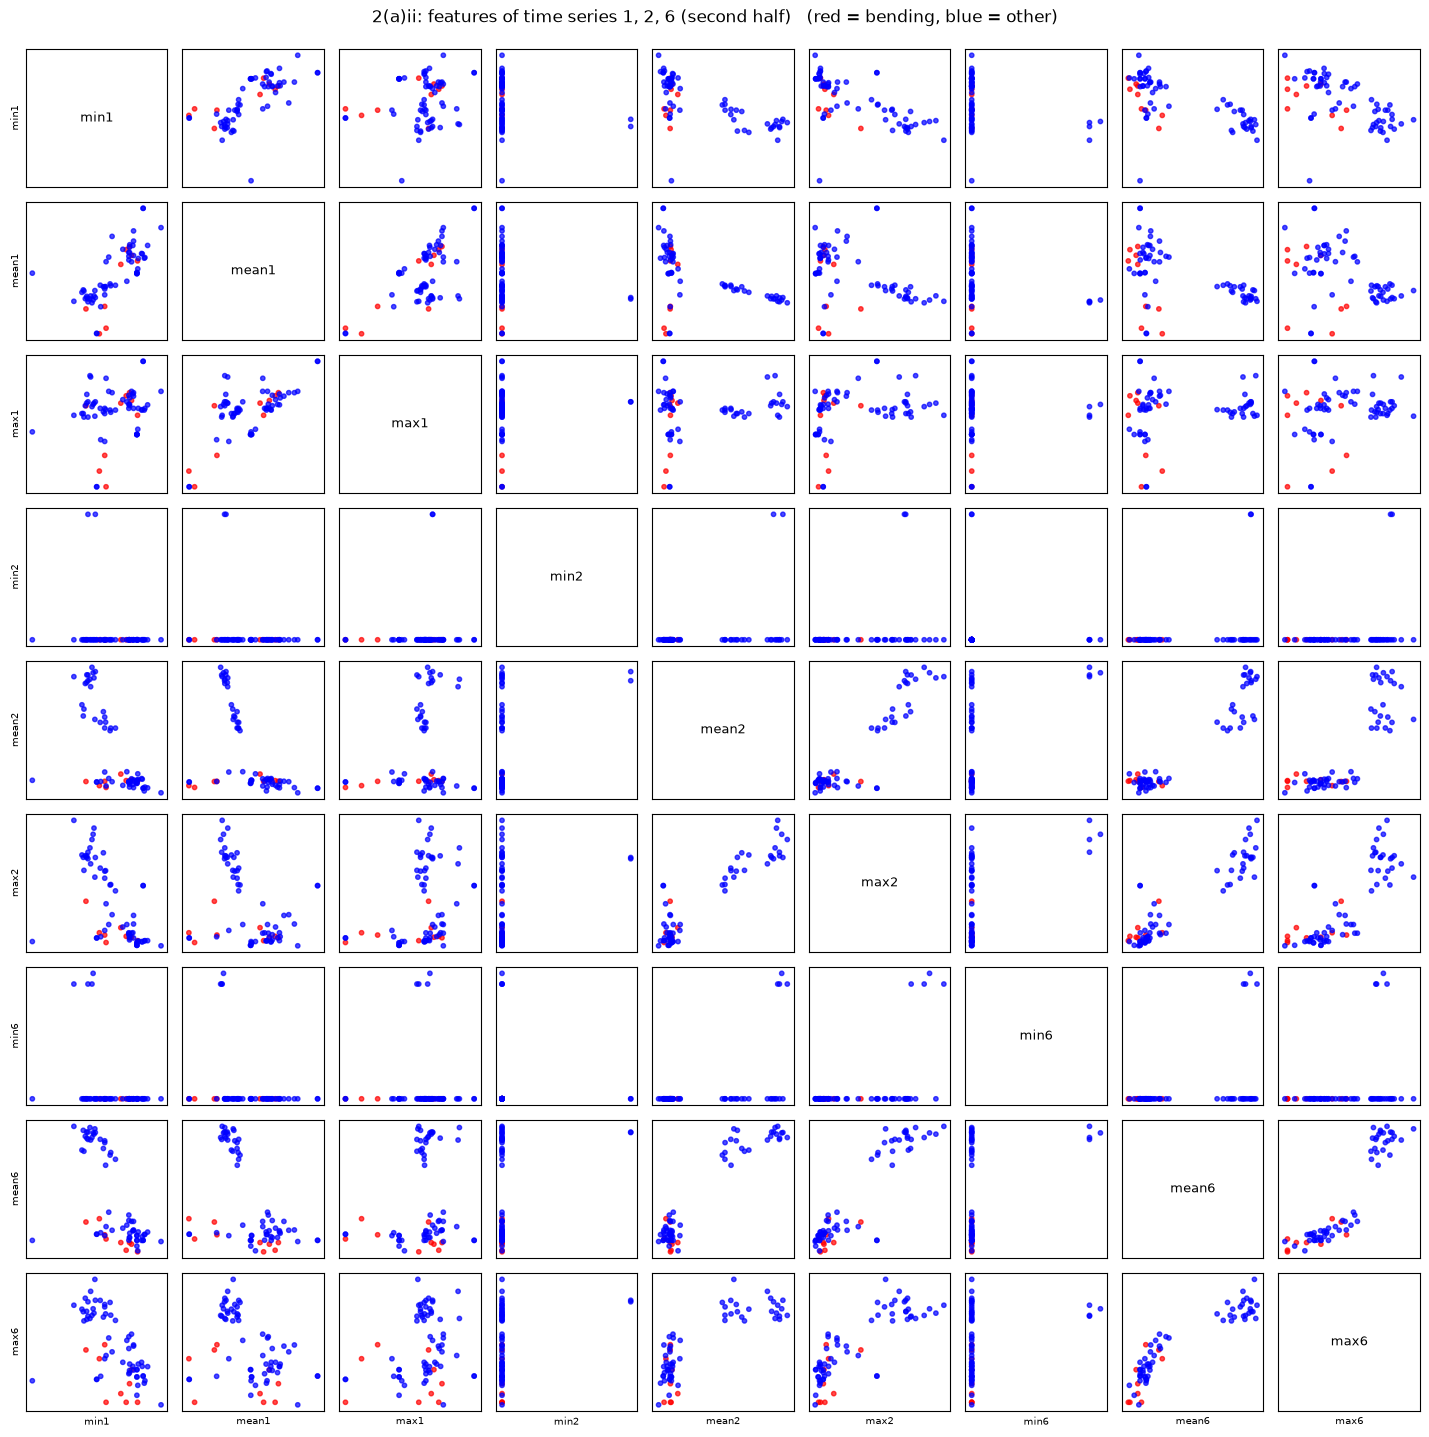

In [5]:
for piece, label in [(1, "first half"), (2, "second half")]:
    idx, labels = columns_for(2, piece=piece)
    scatter_matrix_by_class(FEATS[2][0][is_train][:, idx], labels, y_tr,
                            f"2(a)ii: features of time series 1, 2, 6 ({label})")

**Answer:** No considerable difference is observed. In the plots of the whole series, the first half and the second half, the bending instances lie in the same region, at low values of mean2, max2, mean6 and max6. Many instances of other activities lie in that region as well, so the classes overlap in all three cases. The features min2 and min6 are nearly constant across instances in every version.

### 2(a)iii Choosing (l, p) with 5-fold cross-validation and recursive feature elimination

For every `l` in 1, …, 20 each time series is broken into `l` pieces, giving 18·l features (min, mean, max of 6 series × `l` pieces). Logistic regression is fitted with `C = 10⁶` (no effective L2 penalty) and `max_iter = 100`. Features are eliminated one at a time with recursive feature elimination (RFE), and every `p` from 1 to 18·l is evaluated.

**Right way vs. wrong way to cross-validate.**
- *Right way:* split the **instances** into folds first. Inside each fold, fit the scaler, run RFE (which uses the labels) and fit the model using **only the training part of the fold**, and then score the held-out part. The best pair (l, p) is the one with the best average held-out accuracy. All pieces of an instance stay in the same fold because the folds are defined on instances.
- *Wrong way:* run RFE (or choose the features / p) on the **whole** training set first and then cross-validate the reduced model. The held-out labels have then already influenced which features were selected, so the cross-validation accuracy is optimistically biased. This is especially severe here, where the number of features (up to 360) is far larger than the 69 training instances.

**Stratified cross-validation.** Only 9 of the 69 training instances are bending, so random folds could contain no bending instance. Stratified folds keep the class proportions of the full training set in every fold, so I use stratified 5-fold cross-validation.

**Selection rule.** The best (l, p) has the highest mean cross-validation accuracy; ties are broken by the smaller p, then the smaller l (simplest model).

In [6]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = list(skf.split(np.zeros(len(y_tr)), y_tr))


def lr_plain():
    return LogisticRegression(C=C_BIG, max_iter=MAX_ITER)


def rfe_ranking(X_scaled, y):
    """Backward elimination, one feature at a time.
    ranking_[i] <= p  <=>  feature i is one of the p features that survive longest."""
    return RFE(lr_plain(), n_features_to_select=1, step=1).fit(X_scaled, y).ranking_


rows = []
for l in L_VALUES:
    X = FEATS[l][0][is_train]
    n_feat = X.shape[1]
    acc = {p: [] for p in range(1, n_feat + 1)}
    for tr, va in folds:
        scaler = StandardScaler().fit(X[tr])             # everything is fitted on the fold's
        Xt, Xv = scaler.transform(X[tr]), scaler.transform(X[va])   # training part only
        rank = rfe_ranking(Xt, y_tr[tr])
        for p in acc:
            keep = rank <= p
            model = lr_plain().fit(Xt[:, keep], y_tr[tr])
            acc[p].append(accuracy_score(y_tr[va], model.predict(Xv[:, keep])))
    rows += [(l, p, np.mean(a)) for p, a in acc.items()]

cv_df = pd.DataFrame(rows, columns=["l", "p", "cv_accuracy"])

In [7]:
ranked = cv_df.sort_values(["cv_accuracy", "p", "l"], ascending=[False, True, True]).reset_index(drop=True)
best = ranked.iloc[0]
l_star, p_star, cv_acc_star = int(best["l"]), int(best["p"]), float(best["cv_accuracy"])
print(f"Best (l, p) = ({l_star}, {p_star})   5-fold CV accuracy = {cv_acc_star:.3f}")

Best (l, p) = (18, 1)   5-fold CV accuracy = 0.986


### 2(a)iv Final model on the training data

The scaler, RFE and logistic regression are refitted on the whole training set with the selected (l, p). The p-values are Wald p-values computed from the observed information matrix of the fitted logistic regression (the same quantity `glm` in R reports). Coefficients are for **standardized** features.

Training confusion matrix (l = 18, p = 1)   (accuracy = 0.971)


,pred other,pred bending
true other,59,1
true bending,1,8


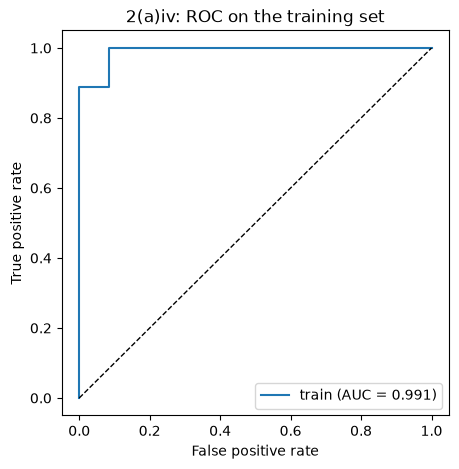

,feature,beta,p_value
0,intercept,-5.499637,0.004140
1,mean_s5_p3,6.964287,0.019745


In [8]:
def wald_pvalues(model, X):
    """Wald p-values for (intercept, coefficients) of a fitted LogisticRegression."""
    Xd = np.column_stack([np.ones(len(X)), X])
    beta = np.r_[model.intercept_, model.coef_.ravel()]
    prob = 1.0 / (1.0 + np.exp(-Xd @ beta))
    W = prob * (1.0 - prob)
    try:
        cov = np.linalg.inv(Xd.T @ (Xd * W[:, None]))
        se = np.sqrt(np.diag(cov))
        return 2 * (1 - norm.cdf(np.abs(beta / se)))
    except np.linalg.LinAlgError:
        return np.full(len(beta), np.nan)


def show_cm(y_true, y_pred, title, labels=("other", "bending")):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    print(f"{title}   (accuracy = {accuracy_score(y_true, y_pred):.3f})")
    display(pd.DataFrame(cm, index=[f"true {s}" for s in labels],
                         columns=[f"pred {s}" for s in labels]))


def plot_roc(curves, title):
    plt.figure(figsize=(5, 5))
    for label, y_true, score in curves:
        fpr, tpr, _ = roc_curve(y_true, score)
        plt.plot(fpr, tpr, label=f"{label} (AUC = {auc(fpr, tpr):.3f})")
    plt.plot([0, 1], [0, 1], "k--", linewidth=1)
    plt.xlabel("False positive rate")
    plt.ylabel("True positive rate")
    plt.title(title)
    plt.legend(loc="lower right")
    plt.show()


X_all, names = FEATS[l_star]
scaler = StandardScaler().fit(X_all[is_train])
Xtr_s, Xte_s = scaler.transform(X_all[is_train]), scaler.transform(X_all[~is_train])
keep = rfe_ranking(Xtr_s, y_tr) <= p_star
model = lr_plain().fit(Xtr_s[:, keep], y_tr)

train_pred = model.predict(Xtr_s[:, keep])
train_score = model.predict_proba(Xtr_s[:, keep])[:, 1]
show_cm(y_tr, train_pred, f"Training confusion matrix (l = {l_star}, p = {p_star})")
plot_roc([("train", y_tr, train_score)], "2(a)iv: ROC on the training set")

coef_table = pd.DataFrame({
    "feature": ["intercept"] + list(np.array(names)[keep]),
    "beta": np.r_[model.intercept_, model.coef_.ravel()],
    "p_value": wald_pvalues(model, Xtr_s[:, keep]),
})
display(coef_table)

### 2(a)v Test set

The test time series are broken into the same `l` pieces, and the scaler, selected features and logistic regression fitted on the training set are applied to them.

In [9]:
test_pred = model.predict(Xte_s[:, keep])
test_score = model.predict_proba(Xte_s[:, keep])[:, 1]
show_cm(y_te, test_pred, "Test confusion matrix")
test_acc_a = accuracy_score(y_te, test_pred)
print(f"5-fold CV accuracy = {cv_acc_star:.3f}   test accuracy = {test_acc_a:.3f}")

Test confusion matrix   (accuracy = 0.895)


,pred other,pred bending
true other,14,1
true bending,1,3


5-fold CV accuracy = 0.986   test accuracy = 0.895


**Answer:** The test accuracy (0.895, 17 of 19 correct) is lower than the cross-validation accuracy (0.986). The test set is small (4 bending instances), so a single misclassification changes the accuracy by about 5 percentage points. The cross-validation accuracy is also likely optimistic, since it is the best value obtained over many (l, p) combinations.

### 2(a)vi Are the classes well separated (instability of the logistic regression)?

**Answer:** No. The classes are not perfectly separable: the training confusion matrix contains 2 errors (1 false positive and 1 false negative), and the training AUC is 0.991 rather than 1. The estimated parameters are moderate (intercept −5.50, slope 6.96 for the standardized feature) and their p-values are small (0.004 and 0.020), so none of the instability associated with perfect separation is present.

### 2(a)vii Class imbalance and case-control sampling

**Answer:** Yes, the classes are imbalanced: in the training confusion matrix of 2(a)iv the "other" row contains 60 instances and the "bending" row only 9, so a classifier that always predicts "other" already has a high accuracy.

**Case-control sampling.** I keep all bending instances (cases) and draw an equal number of "other" instances (controls) at random, fit the logistic regression on this balanced sample (same scaler, same selected features), and then correct the intercept. Sampling by the response changes only the intercept, not the slopes, so with the population proportion π = (bending in the training set)/(training set size) and the sample proportion π̃ = 0.5 the adjusted intercept is
β₀ = β̂₀ + log(π / (1 − π)) − log(π̃ / (1 − π̃)).

Intercept: sample fit = -4.040, adjusted = -5.937
Case-control model, training set   (accuracy = 0.971)


,pred other,pred bending
true other,59,1
true bending,1,8


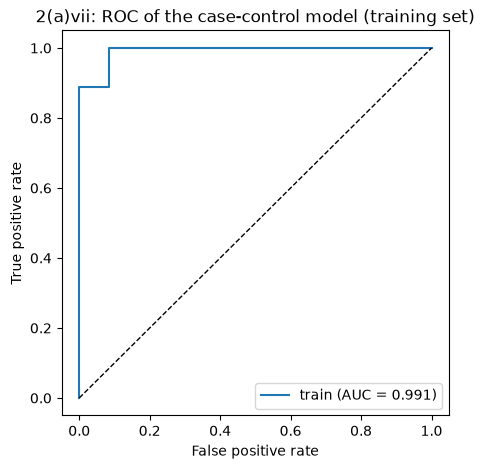

In [10]:
rng = np.random.default_rng(SEED)
cases = np.where(y_tr == 1)[0]
controls = rng.choice(np.where(y_tr == 0)[0], size=len(cases), replace=False)
sample = np.r_[cases, controls]

cc_model = lr_plain().fit(Xtr_s[sample][:, keep], y_tr[sample])
pi, pi_sample = y_tr.mean(), 0.5
b0 = cc_model.intercept_[0] + np.log(pi / (1 - pi)) - np.log(pi_sample / (1 - pi_sample))
beta = cc_model.coef_.ravel()


def cc_score(X_scaled):
    return 1.0 / (1.0 + np.exp(-(X_scaled[:, keep] @ beta + b0)))


print(f"Intercept: sample fit = {cc_model.intercept_[0]:.3f}, adjusted = {b0:.3f}")
cc_train = cc_score(Xtr_s)
show_cm(y_tr, (cc_train >= 0.5).astype(int), "Case-control model, training set")
plot_roc([("train", y_tr, cc_train)], "2(a)vii: ROC of the case-control model (training set)")

## Part 2(b) – Binary classification using L1-penalized logistic regression

### 2(b)i
Features are standardized (inside each cross-validation fold, through a pipeline). For every `l` in 1, …, 20 and every value of `C` (the inverse of the penalty weight λ) on a log grid, I compute the stratified 5-fold cross-validation accuracy of an L1-penalized logistic regression (`liblinear` solver). The best pair (l, C) has the highest accuracy; ties are broken by the smaller C (stronger penalty), then the smaller l.

In [11]:
C_GRID = np.logspace(-2, 2, 9)


def l1_binary(C):
    return make_pipeline(StandardScaler(),
                         l1_logreg(solver="liblinear", C=C, max_iter=1000))


rows = []
for l in L_VALUES:
    X = FEATS[l][0][is_train]
    for C in C_GRID:
        rows.append((l, C, cross_val_score(l1_binary(C), X, y_tr, cv=skf, scoring="accuracy").mean()))

l1_df = pd.DataFrame(rows, columns=["l", "C", "cv_accuracy"])
l1_ranked = l1_df.sort_values(["cv_accuracy", "C", "l"], ascending=[False, True, True]).reset_index(drop=True)
l1_best = l1_ranked.iloc[0]
l1_l, l1_C, l1_cv = int(l1_best["l"]), float(l1_best["C"]), float(l1_best["cv_accuracy"])
print(f"Best (l, C) = ({l1_l}, {l1_C:.3g})   5-fold CV accuracy = {l1_cv:.3f}")

Best (l, C) = (1, 1)   5-fold CV accuracy = 0.986


In [12]:
X_l1 = FEATS[l1_l][0]
l1_model = l1_binary(l1_C).fit(X_l1[is_train], y_tr)
l1_test_acc = accuracy_score(y_te, l1_model.predict(X_l1[~is_train]))
print(f"5-fold CV accuracy = {l1_cv:.3f}   test accuracy = {l1_test_acc:.3f}")

5-fold CV accuracy = 0.986   test accuracy = 1.000


### 2(b)ii L1-penalized logistic regression vs. p-value / RFE selection

In [13]:
comparison = pd.DataFrame({
    "method": ["RFE + logistic regression (2(a))", "L1-penalized logistic regression (2(b))"],
    "best l": [l_star, l1_l],
    "5-fold CV accuracy": [cv_acc_star, l1_cv],
    "test accuracy": [test_acc_a, l1_test_acc],
})
comparison

,method,best l,5-fold CV accuracy,test accuracy
0,RFE + logistic regression (2(a)),18,0.985714,0.894737
1,L1-penalized logistic regression (2(b)),1,0.985714,1.000000


**Which one is easier to implement?** The L1-penalized model. Feature selection is built into the fit and a single hyperparameter `C` is cross-validated (`l` is the only other loop). The RFE / p-value approach needs a nested search over `l` and `p`, an explicit elimination procedure that must be repeated inside every fold, and separate code to obtain p-values.

**Answer:** L1-penalized logistic regression performed better on the test set, with an accuracy of 1.000 (19 of 19 correct) compared with 0.895 for the RFE-based approach, while both reached the same cross-validation accuracy (0.986). Since the test set contains only 19 instances, the difference corresponds to 2 instances.

## Part 2(c) – Multi-class classification (all 7 activities)

The class label is the activity folder (`bending1`, `bending2`, `cycling`, `lying`, `sitting`, `standing`, `walking`).

**Confusion matrix and ROC for more than two classes.** The multi-class confusion matrix is a K × K table whose entry (i, j) counts the instances of true class i predicted as class j (the diagonal holds the correct predictions). ROC curves are defined one-vs-rest: for each class, that class is treated as "positive" and all others as "negative", the predicted probability of the class is used as the score, and one ROC curve (with its AUC) is obtained per class.

In [14]:
y_mtr, y_mte = y_multi[is_train], y_multi[~is_train]


def report_multiclass(name, model, X_train, X_test):
    """Fit on the training set, report test error, confusion matrix and one-vs-rest ROC / AUC."""
    model.fit(X_train, y_mtr)
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)
    test_error = 1 - accuracy_score(y_mte, pred)
    print(f"{name}: test error = {test_error:.3f}")
    cm = confusion_matrix(y_mte, pred, labels=range(len(ACTIVITIES)))
    display(pd.DataFrame(cm, index=[f"true {a}" for a in ACTIVITIES],
                         columns=[f"pred {a}" for a in ACTIVITIES]))

    Y = label_binarize(y_mte, classes=range(len(ACTIVITIES)))
    plt.figure(figsize=(6, 5))
    for k, a in enumerate(ACTIVITIES):
        if Y[:, k].sum() == 0:
            continue
        fpr, tpr, _ = roc_curve(Y[:, k], proba[:, k])
        plt.plot(fpr, tpr, label=f"{a} (AUC = {auc(fpr, tpr):.2f})")
    plt.plot([0, 1], [0, 1], "k--", linewidth=1)
    plt.xlabel("False positive rate")
    plt.ylabel("True positive rate")
    plt.title(f"{name}: one-vs-rest ROC (test set)")
    plt.legend(fontsize=7, loc="lower right")
    plt.show()
    return test_error

### 2(c)i L1-penalized multinomial logistic regression

`l` and `C` are chosen exactly as in 2(b)i (stratified 5-fold cross-validation accuracy, standardized features inside the folds, ties broken by the smaller C and then the smaller l), using the `saga` solver, which supports the L1 penalty with a multinomial loss.

In [15]:
C_GRID_MULTI = np.logspace(-2, 1, 7)


def l1_multinomial(C):
    return make_pipeline(StandardScaler(),
                         l1_logreg(solver="saga", C=C, max_iter=500, tol=1e-3))


rows = []
for l in L_VALUES:
    X = FEATS[l][0][is_train]
    for C in C_GRID_MULTI:
        rows.append((l, C, cross_val_score(l1_multinomial(C), X, y_mtr, cv=skf, scoring="accuracy").mean()))

m_df = pd.DataFrame(rows, columns=["l", "C", "cv_accuracy"])
m_ranked = m_df.sort_values(["cv_accuracy", "C", "l"], ascending=[False, True, True]).reset_index(drop=True)
m_l, m_C, m_cv = int(m_ranked.iloc[0]["l"]), float(m_ranked.iloc[0]["C"]), float(m_ranked.iloc[0]["cv_accuracy"])
print(f"Best (l, C) = ({m_l}, {m_C:.3g})   5-fold CV accuracy = {m_cv:.3f}")

Best (l, C) = (1, 3.16)   5-fold CV accuracy = 0.882


L1-penalized multinomial regression: test error = 0.053


,pred bending1,pred bending2,pred cycling,pred lying,pred sitting,pred standing,pred walking
true bending1,2,0,0,0,0,0,0
true bending2,0,2,0,0,0,0,0
true cycling,0,0,3,0,0,0,0
true lying,0,0,0,3,0,0,0
true sitting,0,0,0,0,3,0,0
true standing,0,0,0,1,0,2,0
true walking,0,0,0,0,0,0,3


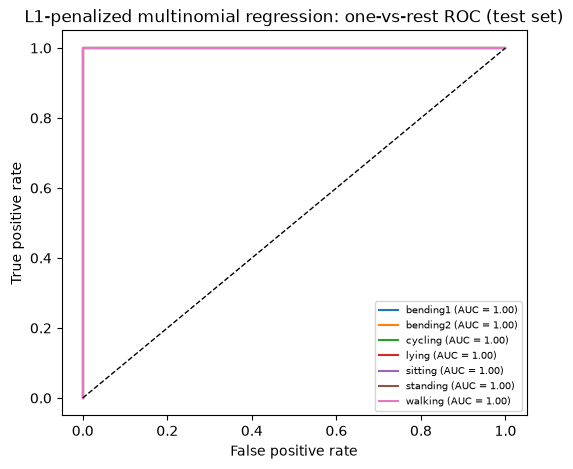

In [16]:
X_m = FEATS[m_l][0]
err_l1 = report_multiclass("L1-penalized multinomial regression",
                           l1_multinomial(m_C), X_m[is_train], X_m[~is_train])

### 2(c)ii Naïve Bayes (Gaussian and Multinomial)

`l` is chosen by the same stratified 5-fold cross-validation. The Gaussian model uses the raw features. The Multinomial model needs non-negative inputs, so the features are min-max scaled to [0, 1] (scaler fitted on the training data; test values are clipped to [0, 1]).

In [17]:
def gaussian_nb():
    return GaussianNB()


def multinomial_nb():
    return make_pipeline(MinMaxScaler(clip=True), MultinomialNB())


def best_l_for(make_model):
    scores = {l: cross_val_score(make_model(), FEATS[l][0][is_train], y_mtr, cv=skf,
                                 scoring="accuracy").mean() for l in L_VALUES}
    l_best = max(scores, key=lambda l: (scores[l], -l))        # ties -> smaller l
    return l_best, scores[l_best]


g_l, g_cv = best_l_for(gaussian_nb)
mn_l, mn_cv = best_l_for(multinomial_nb)
print(f"Gaussian NB:    best l = {g_l}   5-fold CV accuracy = {g_cv:.3f}")
print(f"Multinomial NB: best l = {mn_l}   5-fold CV accuracy = {mn_cv:.3f}")

Gaussian NB:    best l = 2   5-fold CV accuracy = 0.855
Multinomial NB: best l = 6   5-fold CV accuracy = 0.693


Gaussian Naive Bayes: test error = 0.053


,pred bending1,pred bending2,pred cycling,pred lying,pred sitting,pred standing,pred walking
true bending1,2,0,0,0,0,0,0
true bending2,0,2,0,0,0,0,0
true cycling,0,0,3,0,0,0,0
true lying,0,0,0,3,0,0,0
true sitting,0,0,0,0,3,0,0
true standing,0,0,0,0,1,2,0
true walking,0,0,0,0,0,0,3


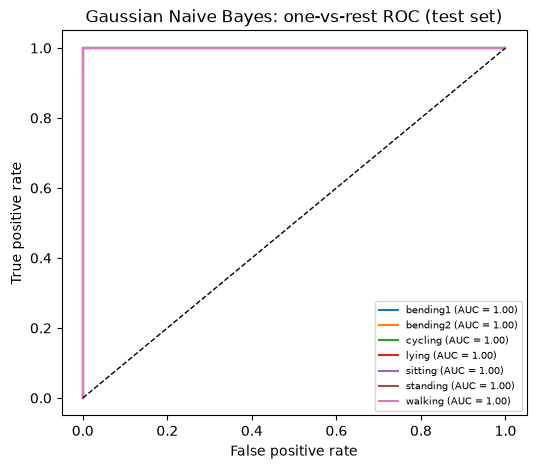

In [18]:
err_g = report_multiclass("Gaussian Naive Bayes", gaussian_nb(),
                          FEATS[g_l][0][is_train], FEATS[g_l][0][~is_train])

Multinomial Naive Bayes: test error = 0.263


,pred bending1,pred bending2,pred cycling,pred lying,pred sitting,pred standing,pred walking
true bending1,2,0,0,0,0,0,0
true bending2,1,0,0,0,1,0,0
true cycling,0,0,3,0,0,0,0
true lying,0,0,1,2,0,0,0
true sitting,0,0,0,0,2,1,0
true standing,0,0,0,0,1,2,0
true walking,0,0,0,0,0,0,3


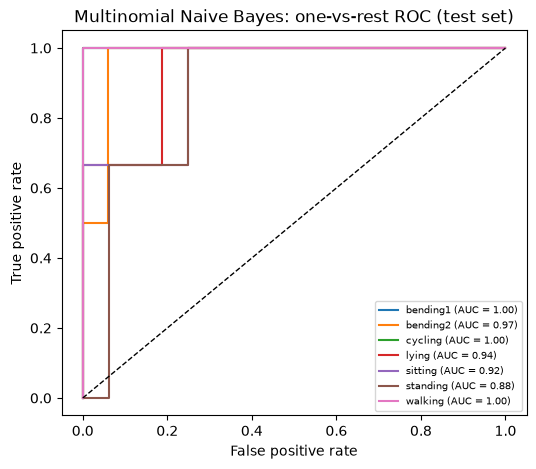

In [19]:
err_mn = report_multiclass("Multinomial Naive Bayes", multinomial_nb(),
                           FEATS[mn_l][0][is_train], FEATS[mn_l][0][~is_train])

### 2(c)iii Which method is better for multi-class classification?

In [20]:
pd.DataFrame({
    "method": ["L1-penalized multinomial regression", "Gaussian Naive Bayes", "Multinomial Naive Bayes"],
    "best l": [m_l, g_l, mn_l],
    "5-fold CV accuracy": [m_cv, g_cv, mn_cv],
    "test error": [err_l1, err_g, err_mn],
})

,method,best l,5-fold CV accuracy,test error
0,L1-penalized multinomial regression,1,0.882418,0.052632
1,Gaussian Naive Bayes,2,0.854945,0.052632
2,Multinomial Naive Bayes,6,0.693407,0.263158


**Answer:** L1-penalized multinomial regression performs best. It achieves the highest cross-validation accuracy (0.882, compared with 0.855 for Gaussian Naive Bayes and 0.693 for Multinomial Naive Bayes) and the same lowest test error as Gaussian Naive Bayes (0.053, 1 of 19 instances). Multinomial Naive Bayes performs worst (test error 0.263), which is consistent with the fact that it models count data, whereas the features used here are continuous.

## Problem 3 – ISLR 4.8.3

Let π_k be the prior of class k and f_k(x) = (1 / (√(2π) σ_k)) · exp(−(x − μ_k)² / (2σ_k²)) the normal density of class k, where each class has its **own** variance σ_k². By Bayes' theorem

p_k(x) = π_k f_k(x) / Σ_l π_l f_l(x).

The Bayes classifier assigns x to the class with the largest p_k(x). The denominator does not depend on k, so this is the class that maximizes log(π_k f_k(x)):

log(π_k f_k(x)) = log π_k − ½ log(2π) − log σ_k − (x − μ_k)² / (2σ_k²).

Dropping the term −½ log(2π), which is the same for every class, and expanding the square gives the discriminant

δ_k(x) = − x² / (2σ_k²) + x μ_k / σ_k² − μ_k² / (2σ_k²) + log π_k − log σ_k.

Because the σ_k² differ across classes, the coefficient of x², −1 / (2σ_k²), is different for every class and does **not** cancel when two classes are compared. Hence δ_k(x) is a **quadratic** function of x, and the Bayes classifier (and its decision boundary) is quadratic, not linear. (If all σ_k² were equal, the x² terms would be identical for all classes and drop out, leaving the linear discriminant of LDA.)

## Problem 4 – ISLR 4.8.7

Let "Yes" = issues a dividend, with π_yes = 0.8, μ_yes = 10, and "No" with π_no = 0.2, μ_no = 0, common variance σ² = 36, and x = 4. By Bayes' theorem (the factor 1/√(2π·36) is common to both densities and cancels):

P(Yes | X = 4) = π_yes e^{−(4 − 10)² / (2·36)} / ( π_yes e^{−(4 − 10)² / (2·36)} + π_no e^{−(4 − 0)² / (2·36)} )

= 0.8 e^{−0.5} / ( 0.8 e^{−0.5} + 0.2 e^{−0.2222} ) = 0.4852 / (0.4852 + 0.1601) ≈ **0.752**.

So the probability that the company issues a dividend is about 75.2%.